# Extensions — Sensibilité au contexte et clients atypiques

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**

Ce notebook complète les Jours 1 à 5 **sans modifier la solution retenue** (CAH de Ward, k = 4).

| Partie | Contenu | Place dans le sujet |
|---|---|---|
| A | Segmentation **sans les variables de contexte économique** : que reste-t-il quand on ne garde que le client ? | Discussion des résultats (Jour 5) |
| B | **Détection d'anomalies** : bruit DBSCAN et Isolation Forest, profil des clients atypiques | Extension optionnelle n° 1 |
| C | **Application Streamlit** affectant un nouveau client à un segment | Extension optionnelle n° 3 |

Comme au Jour 4, `y` ne sert qu'à **décrire** les groupes obtenus, jamais à les construire.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             pairwise_distances_argmin)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import SEED, FIG, TAB, LAB
from src import preprocessing as pp
from src.clustering_utils import knee_point

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

d = pp.prepare_all()
df, idx, y = d["df_clean"], d["idx"], d["y"]
y_bin = (y == "yes").astype(int).values
pos = np.searchsorted(df.index, idx)                       # position des clients de l'échantillon
seg_ref = pd.read_csv(LAB / "segments_population.csv", index_col=0)["segment"]   # solution retenue (S1..S4)
print("Échantillon :", len(idx), "clients ; population :", len(df))

Échantillon : 4000 clients ; population : 41176


# Partie A — Segmentation sans les variables de contexte

## A.1 Pourquoi cette variante ?
Au Jour 5, les segments S1 et S2 se distinguent surtout par le **taux Euribor au moment de l'appel**. Les trois variables de contexte (`cons.price.idx`, `cons.conf.idx`, `euribor3m`) décrivent la **période** du contact, pas le client : un même client appelé à une autre date changerait de segment.

On refait donc la CAH de Ward en ne gardant que les **12 variables qui décrivent le client et sa relation avec la banque** : âge, nombre d'appels, contacts antérieurs, profession, statut marital, études, défaut, prêts, canal, résultat précédent, `contacted_before`. Même prétraitement (one-hot + standardisation), même échantillon, même graine.

Il ne s'agit **pas** de remplacer la solution retenue, mais de mesurer ce qu'elle doit au contexte.

In [3]:
CTX = ["cons.price.idx", "cons.conf.idx", "euribor3m"]
NUM_C = [c for c in pp.ACTIVE_NUM if c not in CTX]
CAT_C = pp.ACTIVE_CAT
prep_c = ColumnTransformer([("num", StandardScaler(), NUM_C),
                            ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), CAT_C)]).fit(df[NUM_C + CAT_C])
Xc_full = prep_c.transform(df[NUM_C + CAT_C])
Xc = Xc_full[pos]
print("Variables actives :", NUM_C + CAT_C)
print("Dimension après encodage :", Xc.shape[1])

Zc = linkage(Xc, method="ward")
rows = []
for k in range(2, 7):
    lab = fcluster(Zc, t=k, criterion="maxclust") - 1
    rates = 100 * pd.Series(y_bin).groupby(lab).mean()
    rows.append({"k": k, "silhouette": silhouette_score(Xc, lab), "Davies-Bouldin": davies_bouldin_score(Xc, lab),
                 "tailles": " / ".join(map(str, np.bincount(lab))),
                 "taux souscr. par cluster (%)": " / ".join(f"{r:.1f}" for r in rates)})
sans_ctx = pd.DataFrame(rows)
sans_ctx.to_csv(TAB / "06_sans_contexte_indices.csv", index=False)
sans_ctx.style.format(precision=3).hide(axis="index")

Variables actives : ['age', 'campaign', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'contacted_before']
Dimension après encodage : 34


k,silhouette,Davies-Bouldin,tailles,taux souscr. par cluster (%)
2,0.282,1.592,569 / 3431,25.0 / 9.0
3,0.200,1.846,569 / 495 / 2936,25.0 / 4.4 / 9.8
4,0.118,2.090,569 / 495 / 991 / 1945,25.0 / 4.4 / 10.2 / 9.6
5,0.124,1.894,34 / 535 / 495 / 991 / 1945,50.0 / 23.4 / 4.4 / 10.2 / 9.6
6,0.082,2.107,34 / 535 / 495 / 991 / 584 / 1361,50.0 / 23.4 / 4.4 / 10.2 / 13.5 / 7.9


**Lecture.** Sans le contexte, la structure la plus nette est encore à k = 2 (silhouette 0,28) : elle sépare les **clients déjà démarchés** (569 clients, 25 % de souscription) de tous les autres. Au-delà, la silhouette chute (0,12 à k = 4) : une fois l'historique mis à part, le profil socio-démographique ne forme **pas de groupes nets**.

On examine malgré tout k = 4 pour le comparer, à nombre égal, à la solution retenue.

In [4]:
K = 4
lab_c = fcluster(Zc, t=K, criterion="maxclust") - 1
cent_c = pd.DataFrame(Xc).groupby(lab_c).mean().values
full_c = pairwise_distances_argmin(Xc_full, cent_c)          # même règle d'extension qu'au Jour 5
print(f"Accord centre le plus proche / Ward sur l'échantillon : {(full_c[pos] == lab_c).mean():.1%}")

# Stabilité bootstrap (mêmes réglages qu'au Jour 4)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(20):
    ib = rng.integers(0, len(Xc), len(Xc))
    boot.append(adjusted_rand_score(lab_c[ib], AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xc[ib])))
print(f"Stabilité bootstrap (ARI moyen) : {np.mean(boot):.2f} ± {np.std(boot):.2f}   (solution retenue : 0,93)")
print(f"ARI avec la solution retenue (population) : {adjusted_rand_score(seg_ref, full_c):.2f}")

t = df.assign(groupe=full_c, souscrit=(df["y"] == "yes").astype(int))
pct = lambda col, vals: 100 * t[col].isin(vals).groupby(t["groupe"]).mean()
prof_c = pd.DataFrame({
    "% des clients": 100 * t["groupe"].value_counts(normalize=True).sort_index(),
    "taux de souscription (%)": 100 * t.groupby("groupe")["souscrit"].mean(),
    "âge moyen": t.groupby("groupe")["age"].mean(),
    "appels (campagne)": t.groupby("groupe")["campaign"].mean(),
    "déjà démarché (%)": pct("poutcome", ["failure", "success"]),
    "célibataire (%)": pct("marital", ["single"]),
    "retraité (%)": pct("job", ["retired"]),
    "défaut inconnu (%)": pct("default", ["unknown"]),
    "mobile (%)": pct("contact", ["cellular"]),
})
prof_c.round(1).to_csv(TAB / "06_sans_contexte_profils.csv")
prof_c.round(1)

Accord centre le plus proche / Ward sur l'échantillon : 86.0%


Stabilité bootstrap (ARI moyen) : 0.58 ± 0.13   (solution retenue : 0,93)
ARI avec la solution retenue (population) : 0.18


,% des clients,taux de souscription (%),âge moyen,appels (campagne),déjà démarché (%),célibataire (%),retraité (%),défaut inconnu (%),mobile (%)
groupe,,,,,,,,,
0,13.5,26.6,40.3,1.9,100.0,33.4,6.6,10.1,92.9
1,10.7,5.3,39.5,7.8,1.2,27.4,2.4,23.7,54.1
2,28.7,8.5,50.3,1.9,0.2,4.9,10.3,44.3,56.6
3,47.2,9.9,33.8,1.8,0.0,40.8,0.2,9.1,61.4


In [5]:
# Correspondance avec les segments de la solution retenue (population complète)
pd.crosstab(t["groupe"], seg_ref, margins=True, margins_name="total")

segment,S1,S2,S3,S4,total
groupe,,,,,
0,0,0,4618,928,5546
1,3668,614,51,64,4397
2,9467,1724,7,613,11811
3,14203,4503,0,716,19422
total,27338,6841,4676,2321,41176


**Les quatre groupes « client ».**

| Groupe | Profil | Lecture |
|---|---|---|
| 0 | Déjà démarchés (100 %), 24 % de succès précédents | Retrouve presque exactement le segment **S3** |
| 1 | **Sur-sollicités** : 7,8 appels en moyenne pendant la campagne | Petit groupe (11 %), souscription faible |
| 2 | Plus âgés (50 ans), mariés, défaut de crédit souvent inconnu | Profil « senior » |
| 3 | Plus jeunes (34 ans), 41 % de célibataires | Profil « jeune actif » |

Deux constats :
- **Seul l'historique de contact survit** à la suppression du contexte : S3 est retrouvé, les autres segments sont redistribués (ARI de 0,18 avec la solution retenue).
- La partition est **moins nette** (silhouette 0,12 contre 0,21) et **beaucoup moins stable** (ARI bootstrap ≈ 0,58 contre 0,93).

Attention à l'interprétation du groupe 1 : `campaign` compte les appels de la campagne en cours, qui s'arrêtent souvent après une souscription. Un grand nombre d'appels est donc en partie une **conséquence** de la non-souscription, pas seulement une caractéristique du client.

## A.2 À période égale, le profil du client compte-t-il encore ?
On croise les groupes « client » avec la période du contact (taux Euribor bas < 3 % ou haut ≥ 3 %).

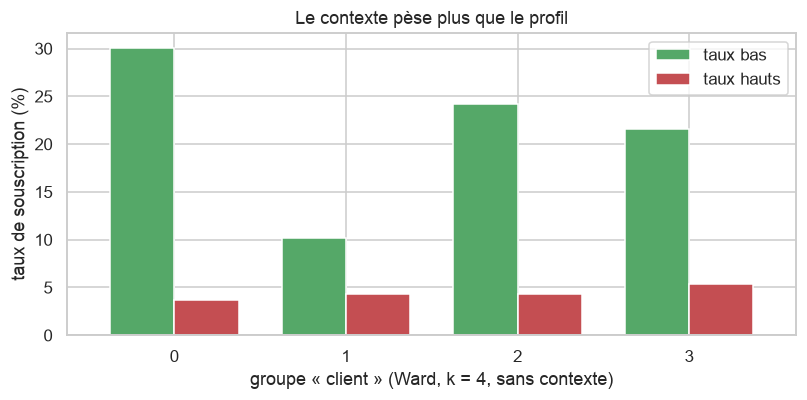

,taux bas : souscription (%),taux bas : clients,taux hauts : souscription (%),taux hauts : clients
groupe,,,,
0,30.1,4816.0,3.7,730.0
1,10.1,749.0,4.4,3648.0
2,24.2,2476.0,4.4,9335.0
3,21.6,5453.0,5.3,13969.0
ensemble,24.5,13494.0,4.8,27682.0


In [6]:
t["période"] = np.where(t["euribor3m"] >= 3, "taux hauts (≥ 3 %)", "taux bas (< 3 %)")
ct = t.pivot_table(index="groupe", columns="période", values="souscrit", aggfunc=["mean", "size"])
ctx_tab = pd.DataFrame({
    "taux bas : souscription (%)": 100 * ct[("mean", "taux bas (< 3 %)")],
    "taux bas : clients": ct[("size", "taux bas (< 3 %)")],
    "taux hauts : souscription (%)": 100 * ct[("mean", "taux hauts (≥ 3 %)")],
    "taux hauts : clients": ct[("size", "taux hauts (≥ 3 %)")],
})
ctx_tab.loc["ensemble"] = [100 * t.loc[t["période"].str.startswith("taux bas"), "souscrit"].mean(),
                           (t["période"].str.startswith("taux bas")).sum(),
                           100 * t.loc[t["période"].str.startswith("taux hauts"), "souscrit"].mean(),
                           (t["période"].str.startswith("taux hauts")).sum()]
ctx_tab.round(1).to_csv(TAB / "06_contexte_vs_profil.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ctx_tab.iloc[:-1][["taux bas : souscription (%)", "taux hauts : souscription (%)"]].plot.bar(ax=ax, color=["#55A868", "#C44E52"], width=0.75)
ax.set_xlabel("groupe « client » (Ward, k = 4, sans contexte)"); ax.set_ylabel("taux de souscription (%)")
ax.set_title("Le contexte pèse plus que le profil"); ax.tick_params(axis="x", rotation=0); ax.legend(["taux bas", "taux hauts"])
plt.tight_layout(); plt.savefig(FIG / "06_contexte_vs_profil.png", bbox_inches="tight"); plt.show()
ctx_tab.round(1)

**Lecture.**
- **Le contexte domine.** Dans chaque groupe, la souscription passe d'environ 4–5 % en période de taux hauts à 10–30 % en période de taux bas. L'écart dû à la période est bien plus grand que l'écart entre profils.
- **À période égale, le profil compte encore, mais par l'historique et la pression d'appels.** En taux bas : 30 % pour les déjà démarchés, 22–24 % pour les deux profils socio-démographiques, 10 % pour les sur-sollicités. Seniors et jeunes actifs ont des taux très proches : la démographie seule discrimine peu.

**Conséquence pour la solution retenue.** Le choix de garder le contexte dans les variables actives est assumé. Ce qui intéresse la banque, c'est de savoir **qui appeler et quand**, et le contexte est le facteur le plus prédictif. Mais il faut présenter S1 et S2 comme des **situations de contact** plutôt que comme des types de clients. Les recommandations « client » robustes sont celles qui portent sur l'historique (S3) et sur la limitation du nombre d'appels.

# Partie B — Clients atypiques (extension n° 1)

Deux détecteurs indépendants, sur l'échantillon de 4 000 clients :
- **Bruit DBSCAN** : mêmes réglages qu'au Jour 3 (espace PCA à 5 composantes, `min_samples = 10`, ε au coude du graphique des k-distances). Un client est atypique s'il n'a pas assez de voisins proches.
- **Isolation Forest** : forêt d'arbres de partition aléatoires sur la représentation (a). Un client est atypique s'il est **isolé en peu de coupures**. Pour comparer les deux méthodes à effort égal, on fixe la proportion d'anomalies (`contamination`) à celle du bruit DBSCAN.

In [7]:
X_a = d["X_a"].values
X_mixed = d["X_mixed"]

Z5 = PCA(n_components=5, random_state=SEED).fit_transform(X_a)
kdist = np.sort(NearestNeighbors(n_neighbors=10).fit(Z5).kneighbors(Z5)[0][:, -1])
EPS = float(kdist[knee_point(kdist)])
noise = DBSCAN(eps=EPS, min_samples=10).fit_predict(Z5) == -1

iso = IsolationForest(n_estimators=300, contamination=noise.mean(), random_state=SEED).fit(X_a)
score = -iso.score_samples(X_a)                 # plus haut = plus atypique
outlier = iso.predict(X_a) == -1

both = noise & outlier
print(f"ε = {EPS:.2f}")
print(f"Bruit DBSCAN     : {noise.sum()} clients ({100 * noise.mean():.1f} %)")
print(f"Isolation Forest : {outlier.sum()} clients")
print(f"Signalés par les deux : {both.sum()}  ({100 * both.sum() / noise.sum():.0f} % du bruit DBSCAN)")

ε = 1.00
Bruit DBSCAN     : 150 clients (3.8 %)
Isolation Forest : 150 clients
Signalés par les deux : 66  (44 % du bruit DBSCAN)


In [8]:
groups = {"bruit DBSCAN": noise, "Isolation Forest": outlier, "les deux": both, "clients ordinaires": ~(noise | outlier)}
def describe(m):
    s = X_mixed[m]
    return {"nb de clients": int(m.sum()),
            "taux de souscription (%)": 100 * y_bin[m].mean(),
            "âge moyen": s["age"].mean(),
            "appels (campagne)": s["campaign"].mean(),
            "contacts antérieurs": s["previous"].mean(),
            "Euribor moyen": s["euribor3m"].mean(),
            "succès précédent (%)": 100 * (s["poutcome"] == "success").mean(),
            "déjà démarché (%)": 100 * (s["contacted_before"] == "yes").mean(),
            "retraité ou étudiant (%)": 100 * s["job"].isin(["retired", "student"]).mean(),
            "téléphone fixe (%)": 100 * (s["contact"] == "telephone").mean()}
atyp = pd.DataFrame({k: describe(m) for k, m in groups.items()})
atyp.round(2).to_csv(TAB / "06_clients_atypiques.csv")
atyp.round(1)

,bruit DBSCAN,Isolation Forest,les deux,clients ordinaires
nb de clients,150.0,150.0,66.0,3766.0
taux de souscription (%),49.3,46.0,56.1,9.2
âge moyen,49.3,43.3,48.5,39.9
appels (campagne),3.5,2.0,2.0,2.4
contacts antérieurs,1.5,1.7,2.5,0.1
Euribor moyen,1.2,1.1,0.9,3.8
succès précédent (%),36.7,57.3,69.7,0.9
déjà démarché (%),42.0,62.0,78.8,1.0
retraité ou étudiant (%),34.0,30.0,45.5,5.2
téléphone fixe (%),16.7,9.3,9.1,36.9


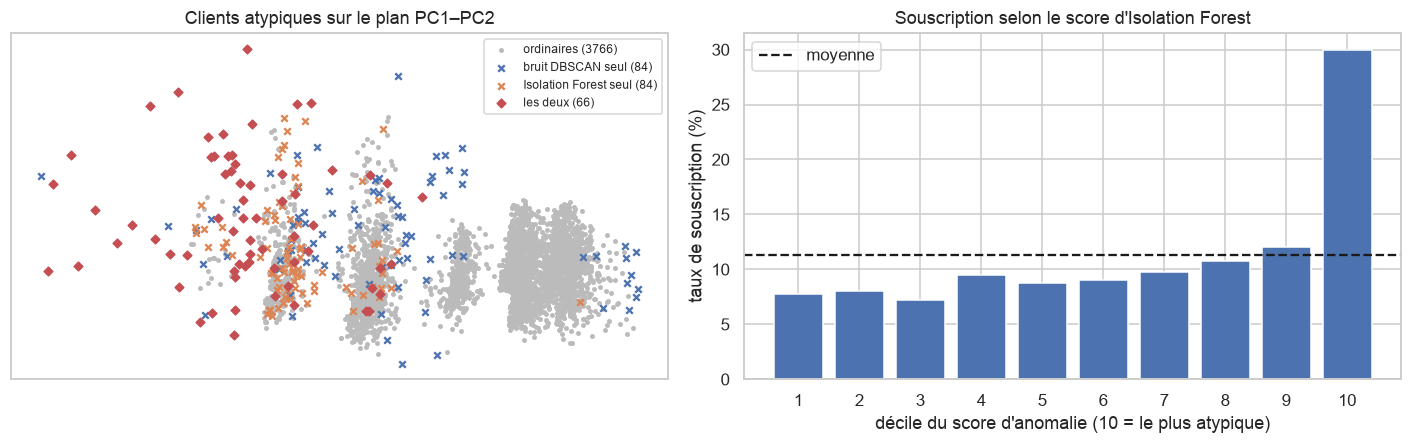

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for m, c, lbl, mk, s in [(~(noise | outlier), "#BBBBBB", "ordinaires", "o", 5), (noise & ~outlier, "#4C72B0", "bruit DBSCAN seul", "x", 18),
                         (outlier & ~noise, "#DD8452", "Isolation Forest seul", "x", 18), (both, "#C44E52", "les deux", "D", 16)]:
    axes[0].scatter(Z5[m, 0], Z5[m, 1], c=c, s=s, marker=mk, label=f"{lbl} ({m.sum()})")
axes[0].set_title("Clients atypiques sur le plan PC1–PC2"); axes[0].legend(fontsize=8); axes[0].set_xticks([]); axes[0].set_yticks([])
dec = pd.qcut(score, 10, labels=False) + 1
rate_dec = 100 * pd.Series(y_bin).groupby(dec).mean()
axes[1].bar(rate_dec.index, rate_dec.values, color="#4C72B0")
axes[1].axhline(100 * y_bin.mean(), ls="--", color="k", label="moyenne")
axes[1].set_xlabel("décile du score d'anomalie (10 = le plus atypique)"); axes[1].set_ylabel("taux de souscription (%)")
axes[1].set_title("Souscription selon le score d'Isolation Forest"); axes[1].set_xticks(range(1, 11)); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "06_clients_atypiques.png", bbox_inches="tight"); plt.show()

**Lecture.**
- Les deux méthodes reposent sur des principes différents (densité locale contre facilité d'isolement), et pourtant **près de la moitié des clients du bruit DBSCAN sont aussi signalés par l'Isolation Forest**. Le noyau commun est donc solide.
- **Les atypiques ne sont pas des erreurs de saisie** : ce sont surtout des clients **déjà démarchés**, souvent avec un **succès précédent**, contactés en période de taux bas. On trouve aussi des retraités et des étudiants.
- Leur taux de souscription avoisine **45–50 %**, soit plus de quatre fois la moyenne. Le taux monte d'ailleurs avec le score d'anomalie.

**Conséquence métier.** Ces clients atypiques ne sont pas à écarter. Ils forment un petit vivier très réceptif, que les méthodes de partitionnement noient dans S3 ou S4. On peut les extraire avec le score d'Isolation Forest et les confier en priorité aux conseillers.

# Partie C — Application Streamlit (extension n° 3)

Le fichier `app/streamlit_app.py` affecte un nouveau client à l'un des quatre segments de la solution retenue, avec la règle du Jour 5 :
1. le client est encodé par le **même préprocesseur** (one-hot + standardisation ajustés sur la population) ;
2. il est affecté au **centre de segment le plus proche** (`outputs/tables/05_centroides_segments.csv`) ;
3. l'application affiche le segment, son taux de souscription observé, la recommandation marketing associée, les distances aux 4 centres et la comparaison du client avec son segment ;
4. elle signale les **clients atypiques** avec l'Isolation Forest de la partie B ;
5. un second onglet affecte un **fichier CSV** entier (format brut UCI accepté, nettoyage du Jour 1 appliqué) et permet de télécharger le résultat.

Lancement, depuis la racine du dépôt :
```bash
streamlit run app/streamlit_app.py
```
La cellule suivante vérifie que la fonction de l'application redonne bien les segments de la population.

In [10]:
sys.path.append("../app")
from streamlit_app import load_model, assign
prep, centroids = load_model()
check = assign(d["X_mixed_full"], prep, centroids)
print(f"Accord avec segments_population.csv : {(check == seg_ref.values).mean():.1%}")

Accord avec segments_population.csv : 100.0%


## Bilan des extensions
1. **Sans contexte**, la clientèle n'a qu'une structure nette : l'historique de contact. Les autres groupes sont flous (silhouette 0,12) et instables (ARI bootstrap ≈ 0,58). À période égale, ce sont l'historique et la pression d'appels qui comptent le plus, plus que le profil socio-démographique.
2. **Clients atypiques** : DBSCAN et Isolation Forest s'accordent sur un noyau de clients déjà démarchés, souvent anciens souscripteurs. Ils souscrivent à près de 50 %.
3. **Application** : la règle du centre le plus proche est déployée dans une petite application Streamlit (un client ou un fichier entier, avec alerte « atypique »).